# 03 · Dataset IMU: EDA, outliers, PCA y clustering
Fuente: Smit et al., DataverseNL, doi:10.34894/PEWAK6 (22 caballos, cojera inducida). Entrada: `data/processed/imu_zancadas.csv`, generado con `src/imu/feature_extraction.py`.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "figuras" / "03_imu_perfiles"; OUT = ROOT / "data" / "processed"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
SEED = 42

df = pd.read_csv(OUT / "imu_zancadas.csv")
df["estado"] = df["cojo"].map({0: "Sano (BAS)", 1: "Cojo (IND)"})
FEATS = [c for c in df.columns if c.endswith(("_mm", "_hr", "_rms")) or c in ["duracion_zancada_s"]]
print(df.shape, "| caballos:", df.id_caballo.nunique(), "| variables:", len(FEATS))
df.groupby(["experimento", "estado"]).agg(zancadas=("zancada", "size"), caballos=("id_caballo", "nunique"))

(1835, 39) | caballos: 22 | variables: 27


zancadas  caballos
experimento estado                        
anterior    Cojo (IND)       357         9
            Sano (BAS)       412        10
posterior   Cojo (IND)       598        12
            Sano (BAS)       468        11

## 1. Calidad: nulos y valores físicamente imposibles

In [2]:
nul = df[FEATS].isna().mean().mul(100).round(2)
print("Variables con nulos (%):\n", nul[nul > 0])
print("\nArchivos sin sensor de cruz:", df.loc[df["cruz_rom_mm"].isna(), "archivo"].unique())

Variables con nulos (%):
 cruz_mindiff_mm    2.29
cruz_rom_mm        2.29
cruz_maxdiff_mm    2.29
cruz_hr            2.29
cruz_acc_rms       2.29
dtype: float64

Archivos sin sensor de cruz: <StringArray>
['HorseG-BAS_HAND.mat']
Length: 1, dtype: str


In [3]:
for c in [c for c in FEATS if c.startswith("cruz_")]:
    df[c] = df[c].fillna(df.groupby(["id_caballo", "condicion"])[c].transform("median"))
    df[c] = df[c].fillna(df.groupby(["experimento", "condicion"])[c].transform("median"))  # respaldo
print("Nulos restantes:", int(df[FEATS].isna().sum().sum()))
artefacto = (~df["duracion_zancada_s"].between(0.45, 0.85)) | (df[[c for c in FEATS if c.endswith("rom_mm")]] > 200).any(axis=1)
print(f"Zancadas artefacto: {artefacto.sum()} ({artefacto.mean()*100:.1f} %)")
df_art = df[artefacto]
df = df[~artefacto].reset_index(drop=True)
print("Zancadas válidas:", len(df))

Nulos restantes: 0
Zancadas artefacto: 18 (1.0 %)
Zancadas válidas: 1817


## 2. Estadística descriptiva por grupo

In [4]:
clave = ["cabeza_mindiff_mm", "cabeza_maxdiff_mm", "sacro_mindiff_mm", "sacro_maxdiff_mm", "hip_hike_diff_mm",
         "cabeza_hr", "sacro_hr", "duracion_zancada_s"]
df.groupby(["experimento", "estado"])[clave].median().T.round(2)

experimento          anterior             posterior           
estado             Cojo (IND) Sano (BAS) Cojo (IND) Sano (BAS)
cabeza_mindiff_mm       31.75      15.79      19.43      16.63
cabeza_maxdiff_mm        4.47       8.29       5.59       8.94
sacro_mindiff_mm         9.30       8.54      17.59       7.17
sacro_maxdiff_mm         1.81       3.48       4.67       3.92
hip_hike_diff_mm         9.31       9.92      19.49      10.37
cabeza_hr                2.46       4.01       3.24       3.80
sacro_hr                 4.18       4.39       3.17       4.01
duracion_zancada_s       0.61       0.61       0.59       0.60

### Pruebas emparejadas por caballo (Wilcoxon)

In [5]:
med = df.groupby(["experimento", "id_caballo", "cojo"])[clave].median().reset_index()
res = []
for exp in ["anterior", "posterior"]:
    m = med[med.experimento == exp].pivot(index="id_caballo", columns="cojo")
    for c in clave:
        par = m[c].dropna()
        if len(par) >= 5:
            w = stats.wilcoxon(par[1], par[0])
            res.append({"experimento": exp, "variable": c, "n_caballos": len(par),
                        "mediana_BAS": par[0].median(), "mediana_IND": par[1].median(),
                        "cambio_%": (par[1].median() / par[0].median() - 1) * 100, "p_valor": w.pvalue})
tests = pd.DataFrame(res)
tests["significativo_0.05"] = tests["p_valor"] < 0.05
tests.round(3)

,experimento,variable,n_caballos,mediana_BAS,mediana_IND,cambio_%,p_valor,significativo_0.05
0,anterior,cabeza_mindiff_mm,9,16.190,31.385,93.850,0.004,True
1,anterior,cabeza_maxdiff_mm,9,10.184,6.096,-40.148,0.203,False
2,anterior,sacro_mindiff_mm,9,8.943,7.975,-10.830,1.000,False
3,anterior,sacro_maxdiff_mm,9,4.924,1.555,-68.422,0.301,False
4,anterior,hip_hike_diff_mm,9,9.906,9.202,-7.114,0.426,False
5,anterior,cabeza_hr,9,4.017,2.504,-37.670,0.004,True
6,anterior,sacro_hr,9,4.785,4.702,-1.741,0.301,False
7,anterior,duracion_zancada_s,9,0.610,0.610,0.000,0.426,False
8,posterior,cabeza_mindiff_mm,11,17.018,17.775,4.447,0.577,False
9,posterior,cabeza_maxdiff_mm,11,10.132,6.525,-35.598,0.320,False


## 3. Visualizaciones

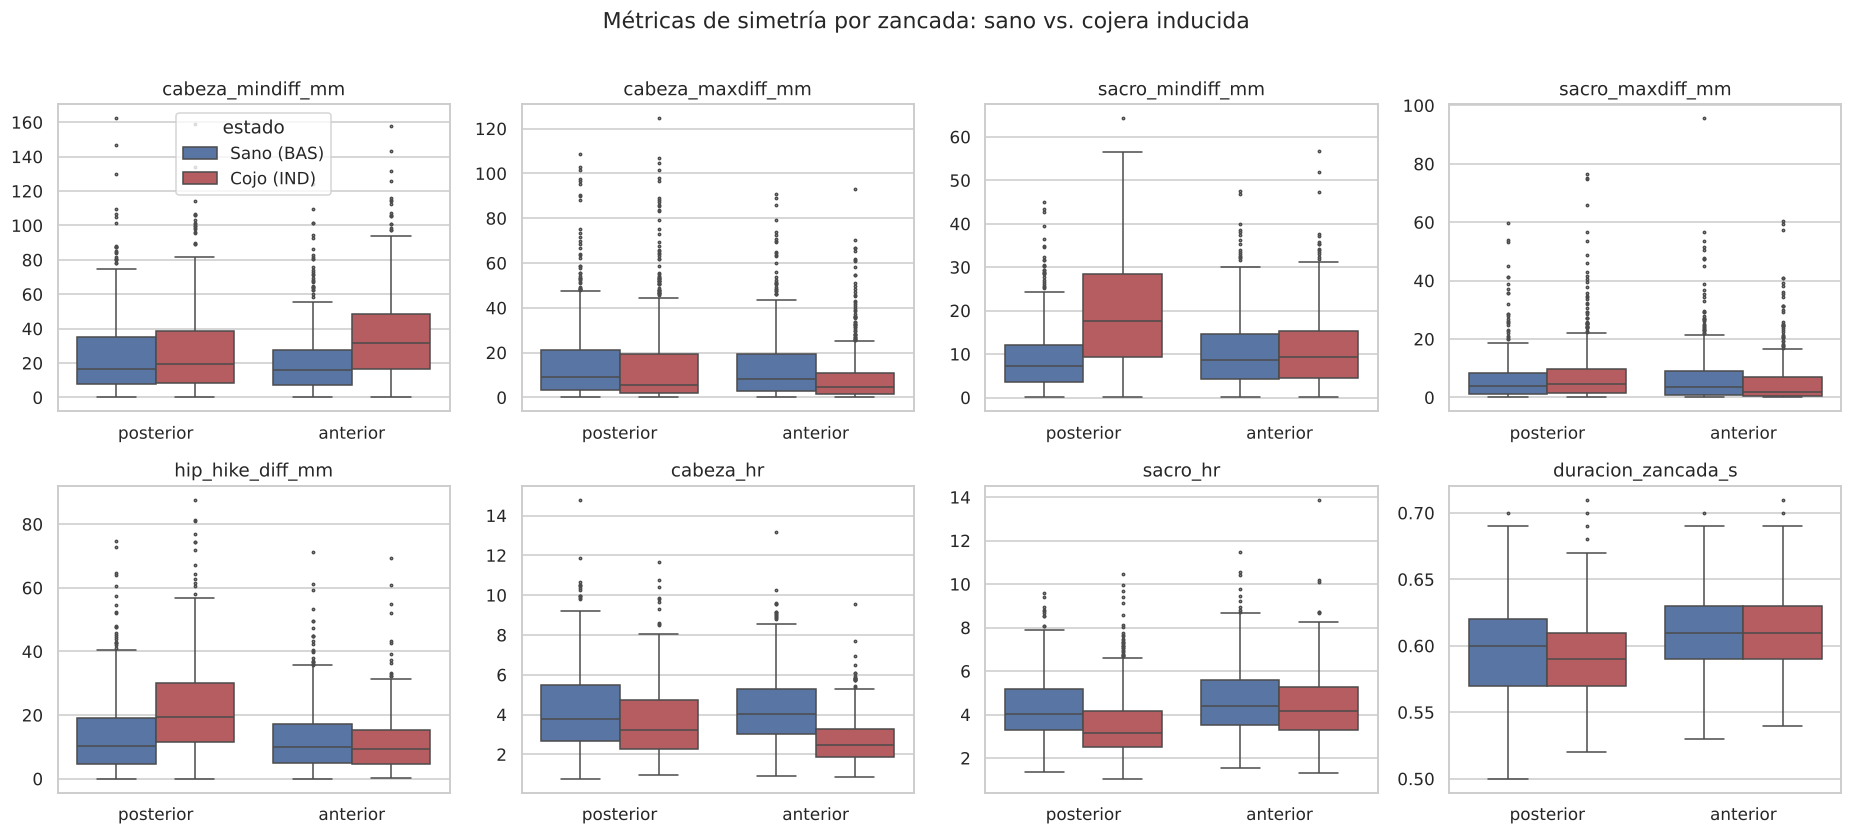

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
for ax, c in zip(axes.ravel(), clave):
    sns.boxplot(data=df, x="experimento", y=c, hue="estado", ax=ax, fliersize=1.5,
                palette={"Sano (BAS)": "#4C72B0", "Cojo (IND)": "#C44E52"})
    ax.set_title(c); ax.set_xlabel(""); ax.set_ylabel("")
    if ax is not axes[0, 0]:
        ax.get_legend().remove()
plt.suptitle("Métricas de simetría por zancada: sano vs. cojera inducida", y=1.01)
plt.tight_layout(); plt.savefig(FIG / "imu_boxplots.png"); plt.show()

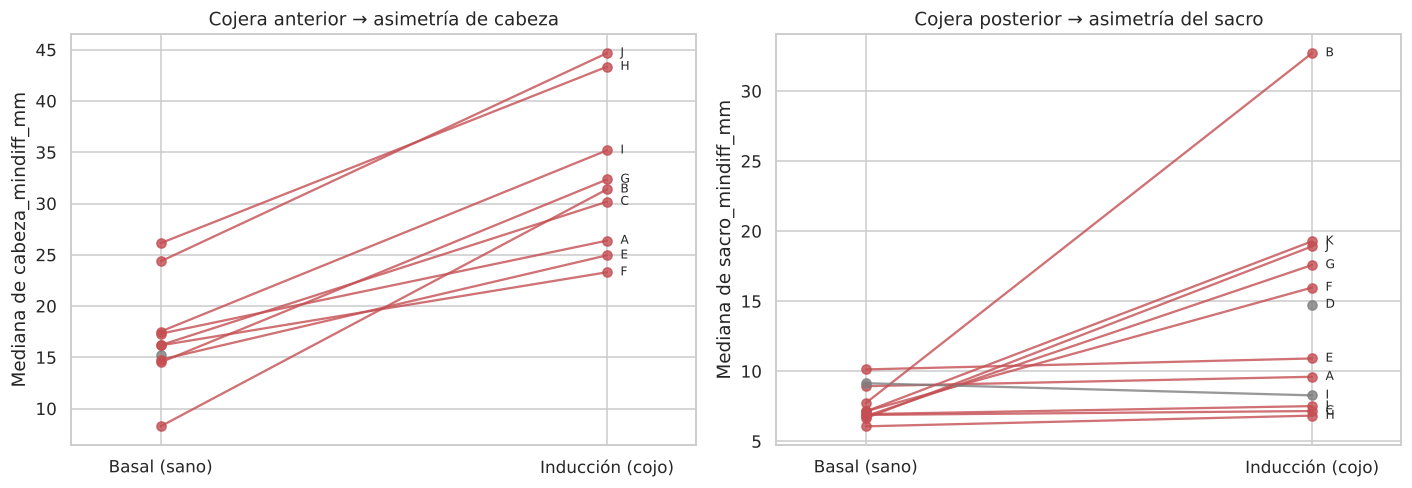

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, (exp, var, tit) in zip(axes, [("anterior", "cabeza_mindiff_mm", "Cojera anterior → asimetría de cabeza"),
                                      ("posterior", "sacro_mindiff_mm", "Cojera posterior → asimetría del sacro")]):
    m = med[med.experimento == exp].pivot(index="id_caballo", columns="cojo", values=var)
    for h, r in m.iterrows():
        color = "#C44E52" if r[1] > r[0] else "#7f7f7f"
        ax.plot([0, 1], [r[0], r[1]], "o-", color=color, alpha=.8)
        ax.text(1.03, r[1], h.split("_")[1], fontsize=8, va="center")
    ax.set_xticks([0, 1], ["Basal (sano)", "Inducción (cojo)"]); ax.set_xlim(-.2, 1.2)
    ax.set_title(tit); ax.set_ylabel(f"Mediana de {var}")
plt.tight_layout(); plt.savefig(FIG / "imu_pareado_caballos.png"); plt.show()

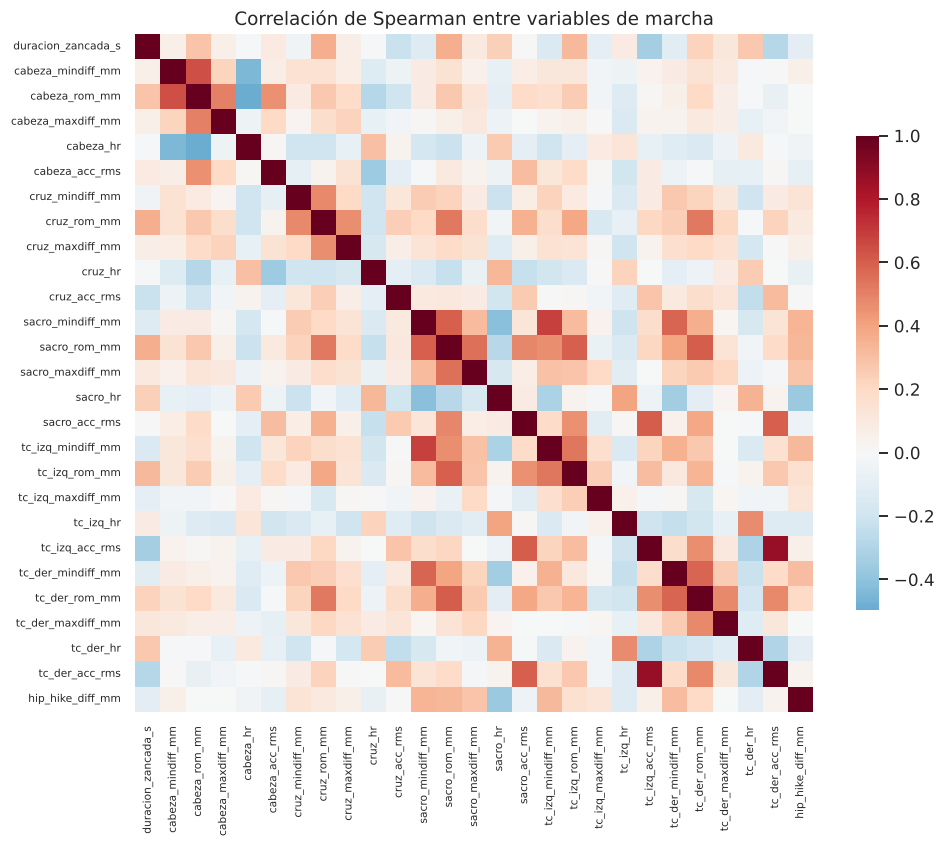

Pares con |rho| > 0.85 (redundancia):
 tc_izq_acc_rms  tc_der_acc_rms    0.87
dtype: float64


In [8]:
plt.figure(figsize=(10, 8))
corr = df[FEATS].corr(method="spearman")
sns.heatmap(corr, cmap="RdBu_r", center=0, square=True, cbar_kws={"shrink": .7}, xticklabels=True, yticklabels=True)
plt.xticks(fontsize=7); plt.yticks(fontsize=7)
plt.title("Correlación de Spearman entre variables de marcha")
plt.savefig(FIG / "imu_correlaciones.png"); plt.show()
alta = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print("Pares con |rho| > 0.85 (redundancia):\n", alta[alta.abs() > 0.85].round(2))

## 4. Outliers: IQR e Isolation Forest

In [9]:
Q1, Q3 = df[clave].quantile(.25), df[clave].quantile(.75)
out_iqr = ((df[clave] < Q1 - 1.5 * (Q3 - Q1)) | (df[clave] > Q3 + 1.5 * (Q3 - Q1)))
df["n_flags_iqr"] = out_iqr.sum(axis=1)
Xs = StandardScaler().fit_transform(df[FEATS])
iso = IsolationForest(n_estimators=300, contamination=0.05, random_state=SEED).fit(Xs)
df["outlier_iforest"] = iso.predict(Xs) == -1
df["score_anomalia"] = -iso.score_samples(Xs)
print("Outliers IQR (≥1 variable):", (df.n_flags_iqr > 0).sum(), "| Isolation Forest:", df.outlier_iforest.sum())
pd.crosstab([df.experimento, df.estado], df.outlier_iforest, normalize="index").mul(100).round(1)

Outliers IQR (≥1 variable): 478 | Isolation Forest: 91


outlier_iforest         False  True 
experimento estado                  
anterior    Cojo (IND)   96.6    3.4
            Sano (BAS)   95.9    4.1
posterior   Cojo (IND)   92.7    7.3
            Sano (BAS)   95.9    4.1

In [10]:
top_h = df[df.outlier_iforest].groupby("id_caballo").size().sort_values(ascending=False)
print("Caballos con más zancadas anómalas:\n", top_h.head(6))
df[df.outlier_iforest].groupby("estado")[clave].median().T.round(1)

Caballos con más zancadas anómalas:
 id_caballo
pos_B    24
pos_C     7
ant_I     5
pos_K     5
ant_A     4
pos_L     4
dtype: int64


estado,Cojo (IND),Sano (BAS)
cabeza_mindiff_mm,42.2,33.9
cabeza_maxdiff_mm,15.5,33.0
sacro_mindiff_mm,34.1,27.9
sacro_maxdiff_mm,23.7,31.4
hip_hike_diff_mm,25.0,29.0
cabeza_hr,2.4,3.4
sacro_hr,2.5,3.0
duracion_zancada_s,0.6,0.6


## 5. PCA: estructura del espacio de características

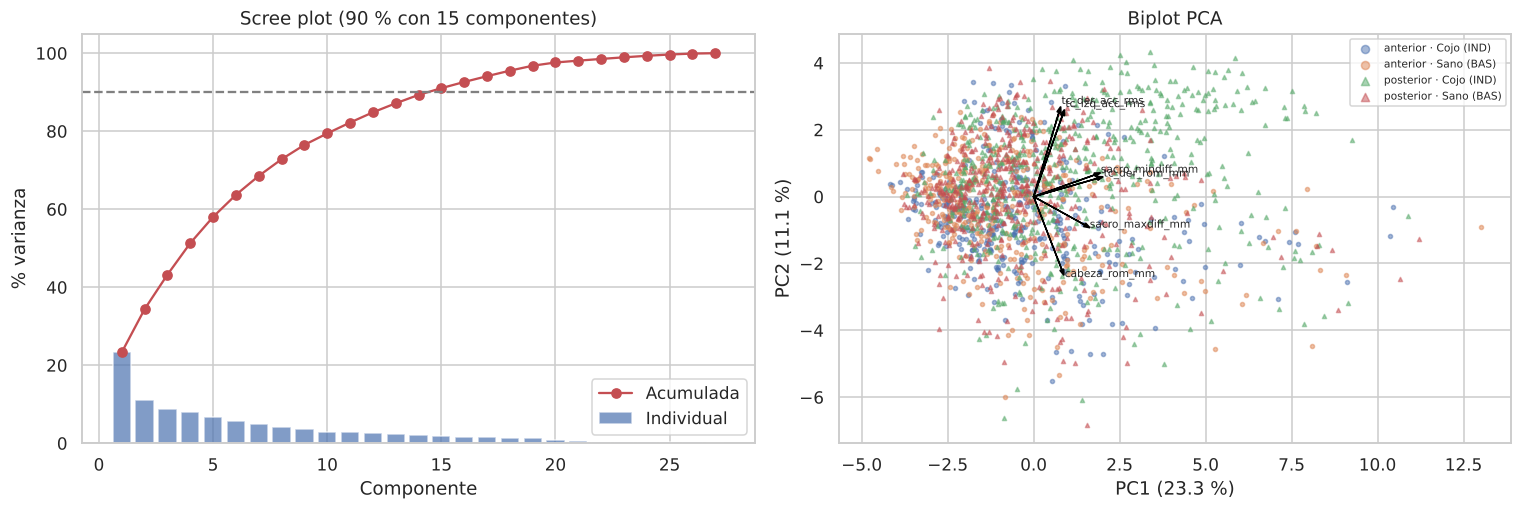

,PC1,PC2,abs_sum
tc_izq_acc_rms,0.14,0.41,0.55
tc_der_acc_rms,0.12,0.42,0.54
cabeza_rom_mm,0.14,-0.36,0.50
sacro_mindiff_mm,0.30,0.11,0.40
tc_der_rom_mm,0.31,0.09,0.40
sacro_maxdiff_mm,0.25,-0.14,0.39
sacro_rom_mm,0.33,-0.06,0.39
tc_der_mindiff_mm,0.28,0.10,0.38


In [11]:
scaler = StandardScaler().fit(df[FEATS])
pca = PCA(random_state=SEED).fit(scaler.transform(df[FEATS]))
Z = pca.transform(scaler.transform(df[FEATS]))
ev = pca.explained_variance_ratio_
n90 = int(np.argmax(ev.cumsum() >= .90) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].bar(range(1, len(ev) + 1), ev * 100, alpha=.7, label="Individual")
axes[0].plot(range(1, len(ev) + 1), ev.cumsum() * 100, "o-", color="#C44E52", label="Acumulada")
axes[0].axhline(90, ls="--", c="gray"); axes[0].set(xlabel="Componente", ylabel="% varianza", title=f"Scree plot (90 % con {n90} componentes)")
axes[0].legend()
for (e, est), g in df.groupby(["experimento", "estado"]):
    idx = g.index
    axes[1].scatter(Z[idx, 0], Z[idx, 1], s=7, alpha=.5, label=f"{e} · {est}",
                    marker="o" if e == "anterior" else "^")
load = pd.DataFrame(pca.components_[:2].T, index=FEATS, columns=["PC1", "PC2"])
for f in load.abs().sum(axis=1).sort_values(ascending=False).index[:6]:
    axes[1].arrow(0, 0, load.loc[f, "PC1"] * 6, load.loc[f, "PC2"] * 6, color="black", head_width=.12)
    axes[1].text(load.loc[f, "PC1"] * 6.6, load.loc[f, "PC2"] * 6.6, f, fontsize=7)
axes[1].set(xlabel=f"PC1 ({ev[0]*100:.1f} %)", ylabel=f"PC2 ({ev[1]*100:.1f} %)", title="Biplot PCA")
axes[1].legend(fontsize=7, markerscale=2)
plt.tight_layout(); plt.savefig(FIG / "imu_pca.png"); plt.show()
load.assign(abs_sum=load.abs().sum(axis=1)).sort_values("abs_sum", ascending=False).head(8).round(2)

## 6. Clustering
### 6.1 K-Means sobre las componentes principales

In [12]:
Zk = Z[:, :n90]
sil = {k: silhouette_score(Zk, KMeans(k, n_init=10, random_state=SEED).fit_predict(Zk), sample_size=1500, random_state=SEED)
       for k in range(2, 9)}
k_best = max(sil, key=sil.get)
print("Silhouette por k:", {k: round(v, 3) for k, v in sil.items()}, "→ k =", k_best)
df["perfil_marcha"] = KMeans(k_best, n_init=20, random_state=SEED).fit_predict(Zk)
display(pd.crosstab([df.experimento, df.estado], df.perfil_marcha, normalize="index").mul(100).round(1))
df.groupby("perfil_marcha")[clave].median().round(1)

Silhouette por k: {2: 0.275, 3: 0.105, 4: 0.109, 5: 0.121, 6: 0.116, 7: 0.12, 8: 0.121} → k = 2


perfil_marcha              0     1
experimento estado                
anterior    Cojo (IND)  85.6  14.4
            Sano (BAS)  87.8  12.2
posterior   Cojo (IND)  63.9  36.1
            Sano (BAS)  87.6  12.4

,cabeza_mindiff_mm,cabeza_maxdiff_mm,sacro_mindiff_mm,sacro_maxdiff_mm,hip_hike_diff_mm,cabeza_hr,sacro_hr,duracion_zancada_s
perfil_marcha,,,,,,,,
0,18.0,6.3,8.3,2.8,10.6,3.6,4.1,0.6
1,28.5,9.7,28.5,10.2,25.4,2.6,2.8,0.6


### 6.2 Clustering jerárquico de caballos (mediana por condición)

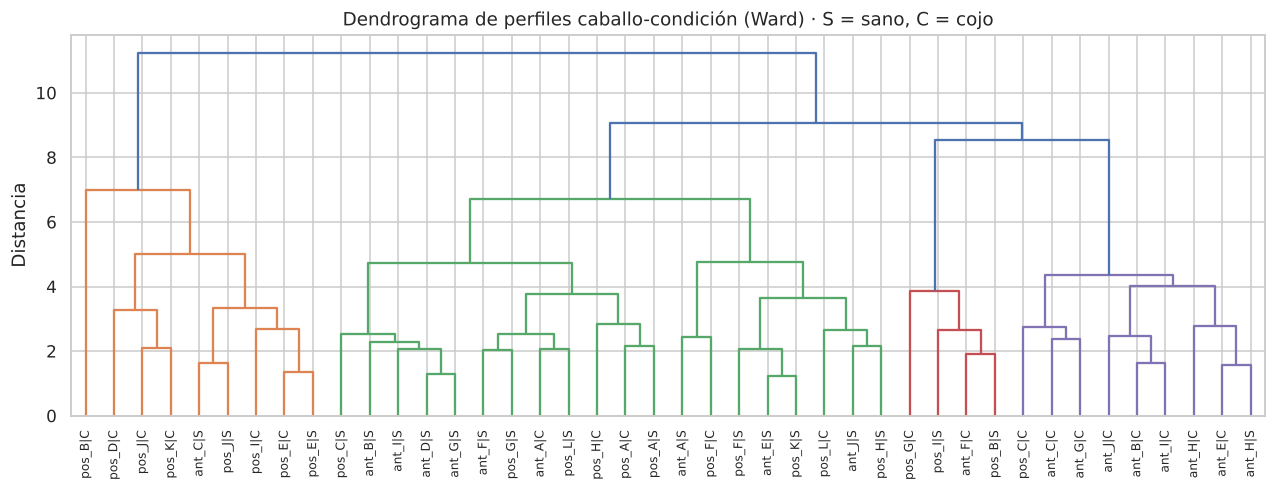

grupo_jerarquico,1,2,3
row_0,,,
Cojo (IND),6,5,10
Sano (BAS),3,15,3


In [13]:
perf = df.groupby(["id_caballo", "estado"])[clave].median()
Zh = linkage(StandardScaler().fit_transform(perf), method="ward")
plt.figure(figsize=(14, 4.5))
dendrogram(Zh, labels=[f"{i}|{'C' if 'Cojo' in e else 'S'}" for i, e in perf.index], leaf_font_size=8, color_threshold=Zh[-3, 2])
plt.title("Dendrograma de perfiles caballo-condición (Ward) · S = sano, C = cojo"); plt.ylabel("Distancia")
plt.savefig(FIG / "imu_dendrograma_caballos.png"); plt.show()
perf["grupo_jerarquico"] = fcluster(Zh, 3, criterion="maxclust")
pd.crosstab(perf.index.get_level_values("estado"), perf["grupo_jerarquico"])

In [14]:
df.to_csv(OUT / "imu_zancadas_limpio.csv", index=False)
print("Guardado imu_zancadas_limpio.csv", df.shape)

Guardado imu_zancadas_limpio.csv (1817, 43)
